 # Set up

In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import umap

PROC = Path("../data/processed")
FIG  = Path("../results/figures"); TAB = Path("../results/tables")

meta   = pd.read_csv(PROC / "meta_clean.csv")
pcs    = pd.read_csv(PROC / "pca_top2000hvg.csv", index_col="sample_id")
logcpm = pd.read_csv(PROC / "logcpm.csv", index_col="gene")
assert (pcs.index == meta["sample_id"]).all()

SUB_ORDER = ["LumA", "LumB", "Her2", "Basal", "Normal"]
PALETTE   = dict(zip(SUB_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]))
sns.set_theme(style="whitegrid", font_scale=1.05)

N_PC = 30        # cluster on the first 30 PCs of the top-2000 HVG
K_FINAL = 4      # final number of clusters (chosen from the plots in cell 2)
X = pcs.iloc[:, :N_PC].values
y = meta["subtype"].values
print("Clustering on", X.shape)


Clustering on (1083, 30)


# choosing k (elbow, silhouette, agreement with PAM50)

       inertia  sil_kmeans  sil_hier  ARI_kmeans  ARI_hier
k                                                         
2   998537.357       0.260     0.264       0.387     0.345
3   881767.397       0.155     0.119       0.343     0.252
4   815868.519       0.152     0.117       0.403     0.351
5   775762.635       0.126     0.103       0.318     0.324
6   749745.195       0.124     0.108       0.331     0.321
7   728062.437       0.102     0.098       0.278     0.300
8   709248.359       0.101     0.078       0.252     0.259
9   691653.881       0.105     0.079       0.235     0.255
10  675149.372       0.091     0.060       0.185     0.190


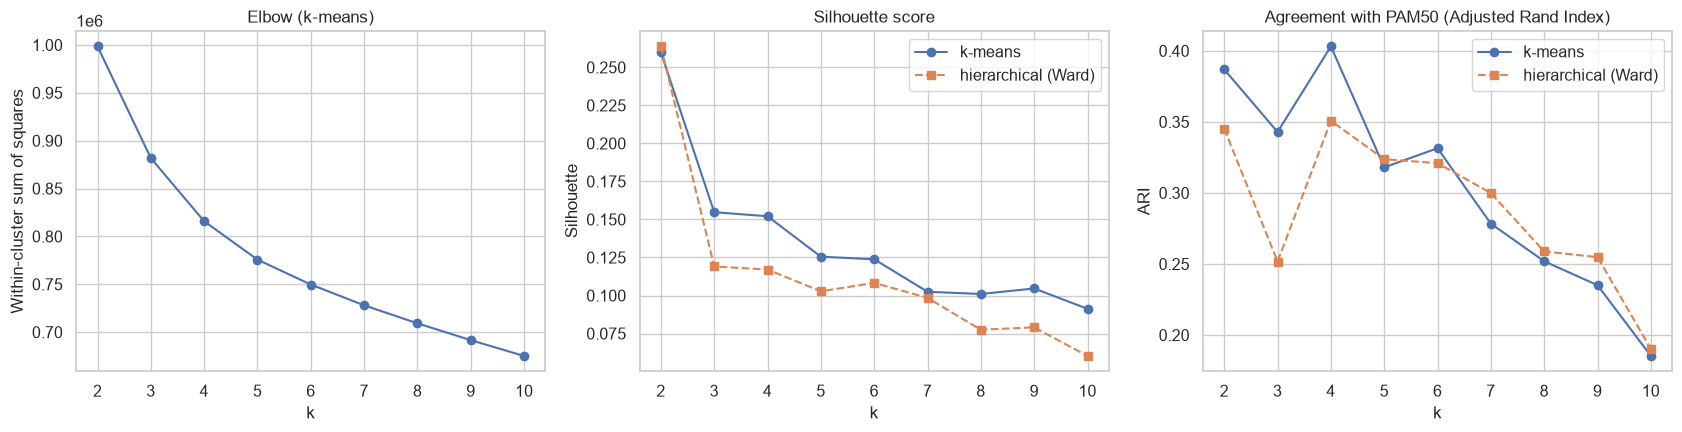

In [10]:
K = range(2, 11)
Z = linkage(X, method="ward")             # hierarchical clustering (Ward linkage, Euclidean)
res = []
for k in K:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    hc = fcluster(Z, k, criterion="maxclust")
    res.append({"k": k, "inertia": km.inertia_,
                "sil_kmeans": silhouette_score(X, km.labels_),
                "sil_hier": silhouette_score(X, hc),
                "ARI_kmeans": adjusted_rand_score(y, km.labels_),
                "ARI_hier": adjusted_rand_score(y, hc)})
res = pd.DataFrame(res).set_index("k")
res.to_csv(TAB / "05_choose_k.csv")
print(res.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(res.index, res["inertia"], "o-"); axes[0].set(title="Elbow (k-means)", xlabel="k", ylabel="Within-cluster sum of squares")
axes[1].plot(res.index, res["sil_kmeans"], "o-", label="k-means")
axes[1].plot(res.index, res["sil_hier"], "s--", label="hierarchical (Ward)")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette"); axes[1].legend()
axes[2].plot(res.index, res["ARI_kmeans"], "o-", label="k-means")
axes[2].plot(res.index, res["ARI_hier"], "s--", label="hierarchical (Ward)")
axes[2].set(title="Agreement with PAM50 (Adjusted Rand Index)", xlabel="k", ylabel="ARI"); axes[2].legend()
for ax in axes: ax.set_xticks(list(K))
plt.tight_layout(); plt.savefig(FIG / "05_choose_k.png", dpi=200); plt.show()

# dendrogram

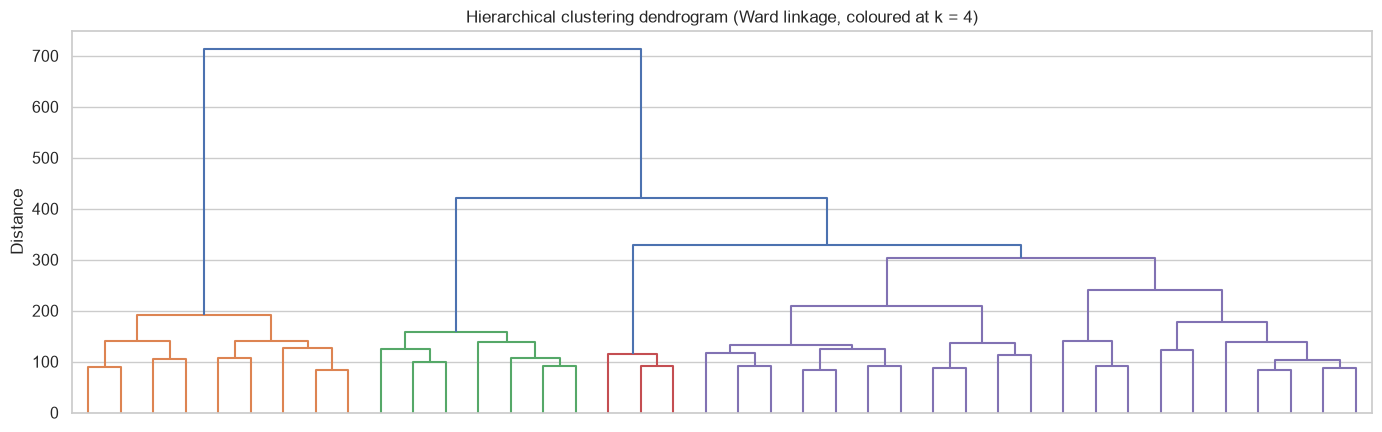

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(Z, truncate_mode="lastp", p=40, ax=ax, no_labels=True,
           color_threshold=(Z[-K_FINAL, 2] + Z[-K_FINAL + 1, 2]) / 2)   # cut height that gives K_FINAL clusters
ax.set(title=f"Hierarchical clustering dendrogram (Ward linkage, coloured at k = {K_FINAL})", ylabel="Distance")
plt.tight_layout(); plt.savefig(FIG / "05_dendrogram.png", dpi=200); plt.show()

# final clusters compared with PAM50

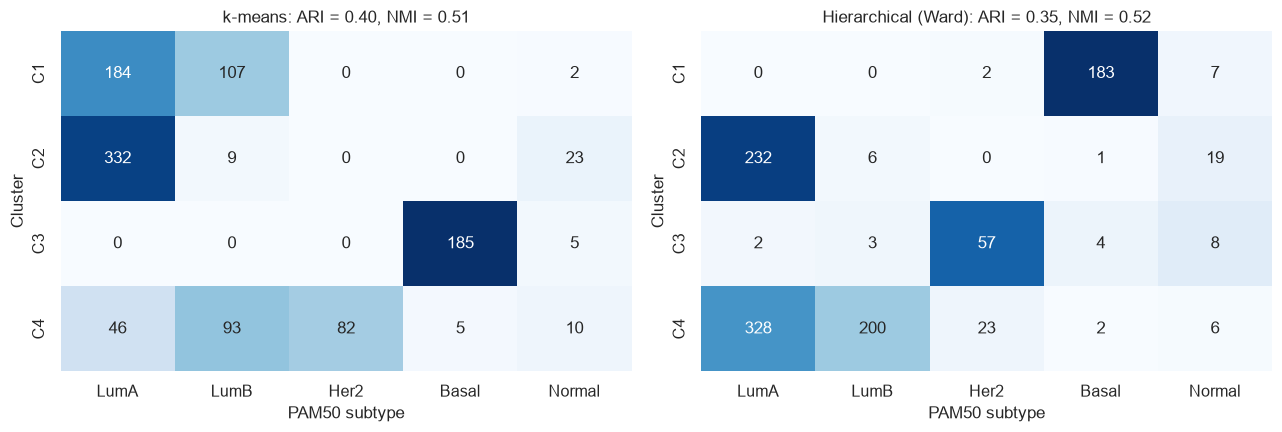

method  k   ARI   NMI  silhouette
kmeans  4 0.403 0.513       0.152
  hier  4 0.351 0.519       0.117


In [12]:
meta["kmeans"] = KMeans(n_clusters=K_FINAL, n_init=20, random_state=42).fit_predict(X) + 1
meta["hier"]   = fcluster(Z, K_FINAL, criterion="maxclust")

summary = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, method in zip(axes, ["kmeans", "hier"]):
    ct = pd.crosstab(meta[method], meta["subtype"])[SUB_ORDER]
    ct.index = [f"C{c}" for c in ct.index]
    ct.to_csv(TAB / f"05_contingency_{method}.csv")
    sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=ct.values, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ari = adjusted_rand_score(meta["subtype"], meta[method])
    nmi = normalized_mutual_info_score(meta["subtype"], meta[method])
    summary.append({"method": method, "k": K_FINAL, "ARI": ari, "NMI": nmi,
                    "silhouette": silhouette_score(X, meta[method])})
    ax.set(title=f"{'k-means' if method == 'kmeans' else 'Hierarchical (Ward)'}: ARI = {ari:.2f}, NMI = {nmi:.2f}",
           xlabel="PAM50 subtype", ylabel="Cluster")
plt.tight_layout(); plt.savefig(FIG / "05_clusters_vs_pam50.png", dpi=200); plt.show()
print(pd.DataFrame(summary).round(3).to_string(index=False))

# UMAP coloured by PAM50 vs by cluster

c:\Users\srika\Downloads\TCGA_BRCA_project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


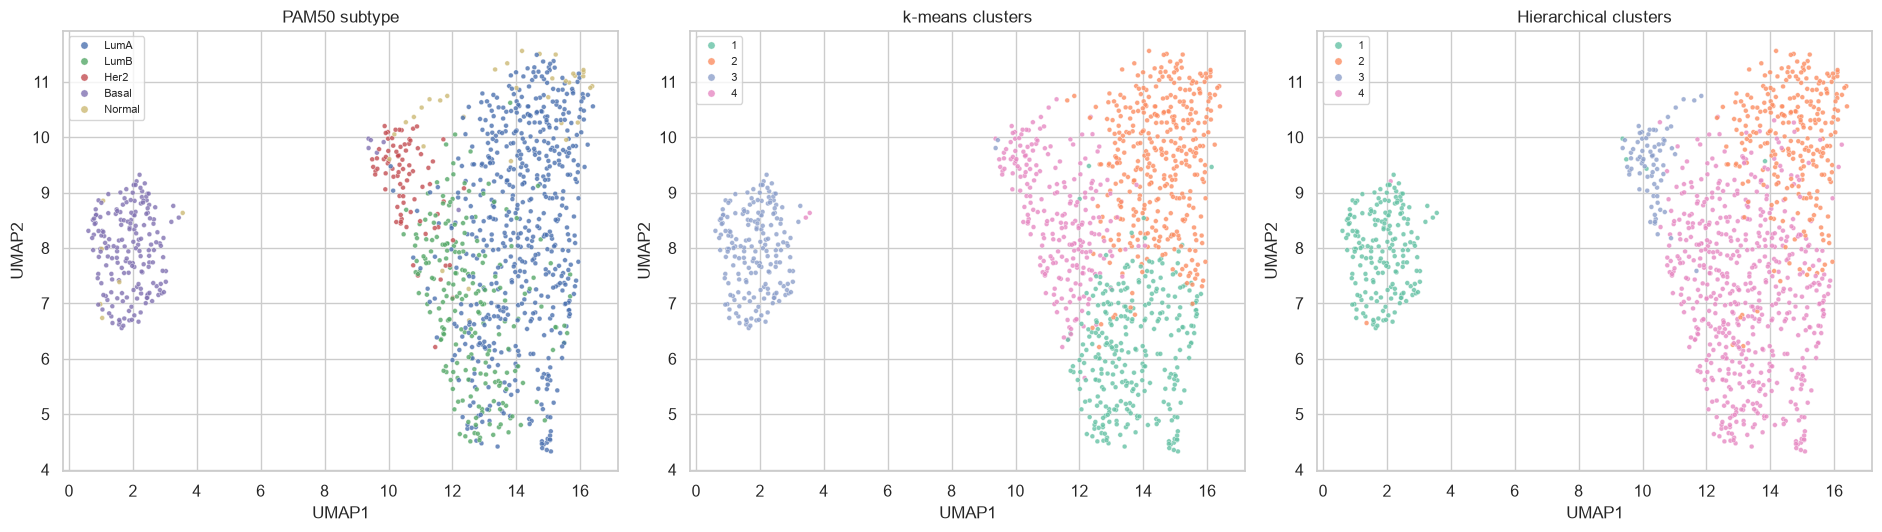

In [13]:
emb = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=42).fit_transform(X)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, col, title in zip(axes, ["subtype", "kmeans", "hier"], ["PAM50 subtype", "k-means clusters", "Hierarchical clusters"]):
    hue = meta[col] if col == "subtype" else meta[col].astype(str)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=hue, s=12, alpha=0.8, ax=ax,
                    hue_order=SUB_ORDER if col == "subtype" else sorted(hue.unique()),
                    palette=PALETTE if col == "subtype" else "Set2")
    ax.set(title=title, xlabel="UMAP1", ylabel="UMAP2"); ax.legend(fontsize=8, markerscale=1.5)
plt.tight_layout(); plt.savefig(FIG / "05_umap_clusters.png", dpi=200); plt.show()

# what characterises each cluster

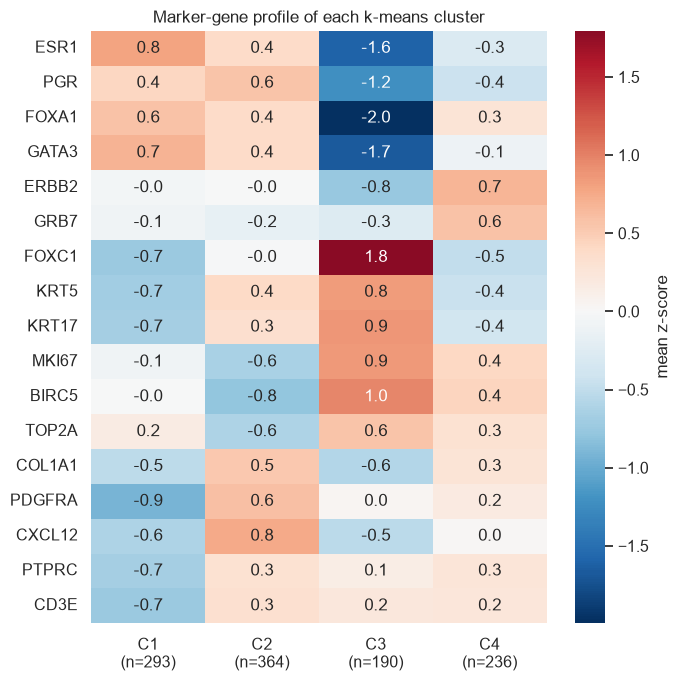

In [14]:
signature_genes = ["ESR1", "PGR", "FOXA1", "GATA3", "ERBB2", "GRB7", "FOXC1", "KRT5", "KRT17",
                   "MKI67", "BIRC5", "TOP2A", "COL1A1", "PDGFRA", "CXCL12", "PTPRC", "CD3E"]
z = logcpm.loc[signature_genes].T
z = (z - z.mean()) / z.std()
prof = z.groupby(meta["kmeans"].values).mean().T
prof.columns = [f"C{c}\n(n={(meta['kmeans'] == c).sum()})" for c in prof.columns]
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(prof, cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax, cbar_kws={"label": "mean z-score"})
ax.set(title="Marker-gene profile of each k-means cluster", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "05_cluster_profiles.png", dpi=200); plt.show()

meta[["sample_id", "subtype", "kmeans", "hier"]].to_csv(PROC / "clusters.csv", index=False)